### Imports

In [28]:
import networkx as nx
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

from utils.graph import (
    create_event_graph,
    create_object_graph,
    create_ocel_graph,
    display_pyvis,
)

### Catboost



[Predictive Analytics for Object-Centric Processes: Do Graph Neural Networks Really Help?](https://link.springer.com/chapter/10.1007/978-3-031-50974-2_39)

[Object-centric process predictive analytics](https://www.sciencedirect.com/science/article/pii/S0957417422021911)

| Process | KPI to predict | Object Type |
| :--- | :--- | :--- |
| Order Management | Time until Order is fulfilled | Order |
| Order Management | Time until the Item is delivered | Item |
| Order Management | Time until the Package is delivered | Package |
| Logistics | Time until the second to last event in the process execution | Order |
| Logistics | Time until the TD is fulfilled | Transport Document |
| Logistics | Time until Container is ready to depart | Container |
| IoT | Time until the Pickup Plan is fulfilled | Pickup Plan |

In [2]:
event_log_path = 'C:/Users/Pavel/Desktop/PhD/OCEL/event_logs/order_management.xml'

ocel_graph, objects_df, events_df, relations_df = create_ocel_graph(event_log_path)

c:\Users\Pavel\Desktop\PhD\OCEL\.venv\lib\site-packages\pm4py\util\dt_parsing\parser.py:82: UserWarning: ISO8601 strings are not fully supported with strpfromiso for Python versions below 3.11
  warnings.warn(


Extracting the KPI from the event log

In [3]:
# event-to-object relations by object type
order_rels = relations_df[relations_df['ocel:type'] == 'orders'][
    ['ocel:eid', 'ocel:oid']
].rename(columns={'ocel:oid': 'order_id'})
item_rels = relations_df[relations_df['ocel:type'] == 'items'][
    ['ocel:eid', 'ocel:oid']
].rename(columns={'ocel:oid': 'item_id'})
package_rels = relations_df[relations_df['ocel:type'] == 'packages'][
    ['ocel:eid', 'ocel:oid']
].rename(columns={'ocel:oid': 'package_id'})

# dependencies through shared events (order -> item -> package)
order_items = pd.merge(order_rels, item_rels, on='ocel:eid')[
    ['order_id', 'item_id']
].drop_duplicates()
item_packages = pd.merge(item_rels, package_rels, on='ocel:eid')[
    ['item_id', 'package_id']
].drop_duplicates()
order_packages = pd.merge(order_items, item_packages, on='item_id')[
    ['order_id', 'package_id']
].drop_duplicates()

# link delivery events and packages
deliveries = events_df[events_df['ocel:activity'] == 'package delivered'][
    ['ocel:eid', 'ocel:timestamp']
]
package_deliveries = pd.merge(package_rels, deliveries, on='ocel:eid')[
    ['package_id', 'ocel:timestamp']
]


def calculate_complete_fulfillment(group):
    # missing delivery timestamps in this order's group
    if group['ocel:timestamp'].isna().any():
        return pd.NaT
    else:
        # all packages delivered and order is fulfilled at the time of the LAST delivery
        return group['ocel:timestamp'].max()


# join orders with their delivery timestamps through packages if all packages delivered
order_fulfillment = pd.merge(
    order_packages, package_deliveries, on='package_id', how='left'
)
kpi_df = (
    order_fulfillment.groupby('order_id')
    .apply(calculate_complete_fulfillment, include_groups=False)
    .reset_index(name='fulfillment_time')
)

kpi_df.head()

,order_id,fulfillment_time
0,o-990001,2023-04-11 09:03:27+00:00
1,o-990002,2023-04-11 09:03:27+00:00
2,o-990003,2023-04-26 09:29:18+00:00
3,o-990004,2023-04-24 09:25:23+00:00
4,o-990005,2023-04-11 09:03:27+00:00


In [6]:
example_order_id = 'o-990720'
example_order_id = 'o-990088'  # cyclic graph of events
example_kpi = kpi_df[kpi_df['order_id'] == example_order_id]['fulfillment_time'].values[
    0
]

example_order_nodes = nx.ego_graph(ocel_graph, example_order_id, radius=2).nodes()
example_order_graph = ocel_graph.subgraph(example_order_nodes).copy()

display_pyvis(
    example_order_graph,
    highlight_node_id=example_order_id,
    output_file_path='outputs/example_order.html',
)

print(f'KPI for order {example_order_id}: {example_kpi}')

KPI for order o-990088: 2023-05-25T16:14:27.000000000


Packages are not visible at 2 hops. More than 2 hops creates a graph that is too large to be visualized due to:
- products-orders M2M
- employees-orders M2M
- customers-orders M2M.

Solution would be to only display order items and the events connected to them within the order.

In [7]:
example_order_items = order_items[order_items['order_id'] == example_order_id][
    'item_id'
].tolist()
example_order_packages = order_packages[order_packages['order_id'] == example_order_id][
    'package_id'
].tolist()

base_objects = [example_order_id] + example_order_items + example_order_packages

example_order_events = (
    relations_df[relations_df['ocel:oid'].isin(base_objects)]['ocel:eid']
    .unique()
    .tolist()
)

peripheral_relations = relations_df[
    (relations_df['ocel:eid'].isin(example_order_events))
    & (relations_df['ocel:type'].isin(['products', 'employees', 'customers']))
]
peripheral_objects = peripheral_relations['ocel:oid'].unique().tolist()

all_isolated_nodes = base_objects + peripheral_objects + example_order_events

example_order_graph = ocel_graph.subgraph(all_isolated_nodes).copy()

display_pyvis(
    example_order_graph,
    highlight_node_id=example_order_id,
    output_file_path='outputs/example_order.html',
)

We only display objects from the order graph

In [43]:
example_order_objects_graph = create_object_graph(example_order_graph)

display_pyvis(
    example_order_objects_graph,
    output_file_path='outputs/example_order_objects.html',
)

or keep only items, products, packages, and orders (if necessary).

In [44]:
allowed_types = ['orders', 'items', 'packages', 'products']

filtered_objects_graph = create_object_graph(
    example_order_graph, allowed_types=allowed_types
)

display_pyvis(
    filtered_objects_graph,
    highlight_node_id=example_order_id,
    output_file_path='outputs/filtered_example_order_objects.html',
)

Make the event graph directed by adding edges between events that share an object, in chronological order.

In [8]:
example_order_events_graph = create_event_graph(
    example_order_graph, nodes=all_isolated_nodes
)

display_pyvis(
    example_order_events_graph,
    output_file_path='outputs/example_order_events_directed.html',
)

Also, may be interested in taking a look at the events with corresponding objects.

In [32]:
example_order_events_objects_graph = create_event_graph(
    example_order_graph,
    nodes=all_isolated_nodes,
    include_objects=True,
    allowed_obj_types=allowed_types,
)

display_pyvis(
    example_order_events_objects_graph,
    output_file_path='outputs/example_order_events_objects.html',
)

Finally, it is possible to extract features from the event log for predictive model. In our case it is going to be CatBoost.

In [21]:
def extract_features_from_graph(directed_event_graph, objects_df, kpi_df, order_id):
    """
    Extract features from a directed event graph
    and related objects for a specific order.
    """

    # print(order_id)
    fulfillment_row = kpi_df[kpi_df['order_id'] == order_id]
    if fulfillment_row.empty:
        return pd.DataFrame()

    fulfillment_time = fulfillment_row['fulfillment_time'].iloc[0]

    sorted_events = list(nx.topological_sort(directed_event_graph))

    dataset = []
    activity_counts = {}
    encountered_objects = set()

    for i, event_id in enumerate(sorted_events):
        event_data = directed_event_graph.nodes[event_id]
        current_time = pd.to_datetime(event_data['ocel:timestamp'])
        current_activity = event_data.get('ocel:activity')

        remaining_time = (fulfillment_time - current_time).total_seconds()

        # If KPI event happened before the current event, skip this prefix
        if remaining_time < 0:
            continue

        activity_counts[current_activity] = activity_counts.get(current_activity, 0) + 1

        if i > 0:
            prev_event = sorted_events[i - 1]
            if directed_event_graph.has_edge(prev_event, event_id):
                shared_objs = directed_event_graph[prev_event][event_id].get(
                    'shared_objects', []
                )
                encountered_objects.update(shared_objs)

        prefix_objects_df = objects_df[objects_df['ocel:oid'].isin(encountered_objects)]

        object_counts = prefix_objects_df['ocel:type'].value_counts().to_dict()

        num_cols = prefix_objects_df.select_dtypes(include=[np.number]).columns
        num_aggregations = (
            prefix_objects_df[num_cols].mean().to_dict() if not num_cols.empty else {}
        )

        row = {
            'order_id': order_id,
            'prefix_length': i + 1,
            'event_name': current_activity,
            'event_timestamp': current_time,
            'y_true': remaining_time,
        }

        for act, count in activity_counts.items():
            row[f'count_activity_{act}'] = count

        for obj_type, count in object_counts.items():
            row[f'count_object_{obj_type}'] = count

        for col, avg_val in num_aggregations.items():
            row[f'avg_{col}'] = avg_val

        dataset.append(row)

    return pd.DataFrame(dataset)

In [25]:
load_data = False

dataset_df_path = 'C://Users//Pavel//Desktop//PhD//OCEL//event_logs//preprocessed//order_management_flat.csv'

if load_data:
    dataset_df = pd.read_csv(dataset_df_path)

else:
    all_order_features = []

    unique_order_ids = kpi_df['order_id'].unique()
    # unique_order_ids = [unique_order_ids[0]]
    # unique_order_ids = ['o-990088']  # cyclic graph of events

    for order_id in unique_order_ids:
        _order_items = order_items[order_items['order_id'] == order_id][
            'item_id'
        ].tolist()
        _order_packages = order_packages[order_packages['order_id'] == order_id][
            'package_id'
        ].tolist()
        _base_objects = [order_id] + _order_items + _order_packages

        _order_events = (
            relations_df[relations_df['ocel:oid'].isin(_base_objects)]['ocel:eid']
            .unique()
            .tolist()
        )

        _peripheral_relations = relations_df[
            (relations_df['ocel:eid'].isin(_order_events))
            & (relations_df['ocel:type'].isin(['products', 'employees', 'customers']))
        ]
        _peripheral_objects = _peripheral_relations['ocel:oid'].unique().tolist()

        _ocel_nodes = _base_objects + _peripheral_objects + _order_events
        _order_subgraph = ocel_graph.subgraph(_ocel_nodes).copy()
        _order_objects_subgraph = create_object_graph(
            _order_subgraph, allowed_types=['orders', 'items', 'packages', 'products']
        )
        _order_events_subgraph = create_event_graph(_order_subgraph)
        _order_events_objects_subgraph = create_event_graph(
            _order_subgraph,
            include_objects=True,
            allowed_obj_types=['orders', 'items', 'packages', 'products'],
        )

        _order_features_df = extract_features_from_graph(
            directed_event_graph=_order_events_subgraph,
            objects_df=objects_df,
            kpi_df=kpi_df,
            order_id=order_id,
        )

        all_order_features.append(_order_features_df)

        # display_pyvis(
        #     _order_subgraph,
        #     highlight_node_id=order_id,
        #     output_file_path=f'outputs/order_{order_id}.html',
        # )
        # display_pyvis(
        #     _order_objects_subgraph,
        #     output_file_path=f'outputs/order_{order_id}_objects.html',
        # )
        # display_pyvis(
        #     _order_events_subgraph,
        #     output_file_path=f'outputs/order_{order_id}_events.html',
        # )
        # display_pyvis(
        #     _order_events_objects_subgraph,
        #     output_file_path=f'outputs/order_{order_id}_events_objects.html',
        # )

    dataset_df = pd.concat(all_order_features, ignore_index=True)
    dataset_df = dataset_df.fillna(0)

    dataset_df.to_csv(
        dataset_df_path,
        index=False,
    )

    dataset_df.head()

Split is done on trace level. However, that can bring certain bias to the model which for this example we neglect. 

In [ ]:
test_ratio = 1 / 3
validation_ratio = 1 / 5

random_seed = 12345

drop_columns = ['order_id', 'y_true', 'event_timestamp']

unique_orders = dataset_df['order_id'].unique()

orders_train_full, orders_test = train_test_split(
    unique_orders, test_size=test_ratio, random_state=random_seed
)

orders_train_final, orders_val = train_test_split(
    orders_train_full, test_size=validation_ratio, random_state=random_seed
)

df_train = dataset_df[dataset_df['order_id'].isin(orders_train_final)].copy()
df_val = dataset_df[dataset_df['order_id'].isin(orders_val)].copy()
df_test = dataset_df[dataset_df['order_id'].isin(orders_test)].copy()

X_train = df_train.drop(columns=drop_columns)
y_train = df_train['y_true']

X_val = df_val.drop(columns=drop_columns)
y_val = df_val['y_true']

X_test = df_test.drop(columns=drop_columns)
y_test = df_test['y_true']

Hyperparameter optimization with *optuna*.

In [32]:
import catboost as cb
import optuna
from optuna_integration import CatBoostPruningCallback


n_trials = 100
n_warmup_steps = 5
random_seed = 34567
cat_features = ['event_name']


def objective(trial: optuna.Trial) -> float:
    param = {
        'loss_function': 'RMSE',
        'eval_metric': 'MAE',
        'depth': trial.suggest_int('depth', 4, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'l2_leaf_reg': trial.suggest_int('l2_leaf_reg', 1, 10),
        'random_seed': random_seed,
        'od_type': 'Iter',
        'od_wait': 50,  # early stopping
    }

    gbm = cb.CatBoostRegressor(**param)

    pruning_callback = CatBoostPruningCallback(trial, 'MAE')

    gbm.fit(
        X_train,
        y_train,
        cat_features=cat_features,
        eval_set=[(X_val, y_val)],
        verbose=0,
        callbacks=[pruning_callback],
    )

    pruning_callback.check_pruned()

    preds = gbm.predict(X_val)
    mae = mean_absolute_error(y_val, preds)

    return mae


study = optuna.create_study(
    pruner=optuna.pruners.MedianPruner(n_warmup_steps=n_warmup_steps),
    direction='minimize',
)

study.optimize(objective, n_trials=n_trials)

trial = study.best_trial

print(f'Number of finished trials: {len(study.trials)}')
print(f'Best Validation MAE: {trial.value / 3600:.2f} hours')
print('Best Params:')
for key, value in trial.params.items():
    print(f'    {key}: {value}')

[I 2026-11-10 15:18:34,808] A new study created in memory with name: no-name-ed34b902-711b-4d68-abc4-081fa4181c73
C:\Users\Pavel\AppData\Local\Temp\ipykernel_17380\4090033832.py:26: ExperimentalWarning: CatBoostPruningCallback is experimental (supported from v3.0.0). The interface can change in the future.
  pruning_callback = CatBoostPruningCallback(trial, 'MAE')
[I 2026-11-10 15:18:48,378] Trial 0 finished with value: 518466.7832216401 and parameters: {'depth': 7, 'learning_rate': 0.04143300860049907, 'l2_leaf_reg': 4}. Best is trial 0 with value: 518466.7832216401.
C:\Users\Pavel\AppData\Local\Temp\ipykernel_17380\4090033832.py:26: ExperimentalWarning: CatBoostPruningCallback is experimental (supported from v3.0.0). The interface can change in the future.
  pruning_callback = CatBoostPruningCallback(trial, 'MAE')
[I 2026-11-10 15:18:54,980] Trial 1 finished with value: 522307.4735400931 and parameters: {'depth': 9, 'learning_rate': 0.1218596872428563, 'l2_leaf_reg': 4}. Best is tria

Number of finished trials: 100
Best Validation MAE: 143.09 hours
Best Params:
    depth: 8
    learning_rate: 0.14909486441264844
    l2_leaf_reg: 5


In [37]:
train_model = True
catboost_model_path = 'C://Users//Pavel//Desktop//PhD//OCEL//models//outputs//catboost/order_management.cbm'

if train_model:
    print('Training model with best parameters...')
    catboost_model = cb.CatBoostRegressor(
        iterations=1000,
        loss_function='RMSE',
        eval_metric='MAE',
        random_seed=random_seed,
        od_type='Iter',
        od_wait=50,
        **trial.params,
    )

    catboost_model.fit(
        X_train,
        y_train,
        cat_features=cat_features,
        eval_set=[(X_val, y_val)],  # for early stopping
        verbose=False,
        plot=True,
    )
    catboost_model.save_model(catboost_model_path)

else:
    print('Loading pre-trained model...')
    catboost_model = cb.CatBoostRegressor()
    catboost_model.load_model(catboost_model_path)


test_preds = catboost_model.predict(X_test)
test_mae = mean_absolute_error(y_test, test_preds)
test_rmse = np.sqrt(mean_squared_error(y_test, test_preds))

print(f'Test MAE:  {test_mae / 3600:.2f} hours')
print(f'Test RMSE: {test_rmse / 3600:.2f} hours')

Training model with best parameters...


MetricVisualizer(layout=Layout(align_self='stretch', height='500px'))

Test MAE:  168.29 hours
Test RMSE: 257.36 hours


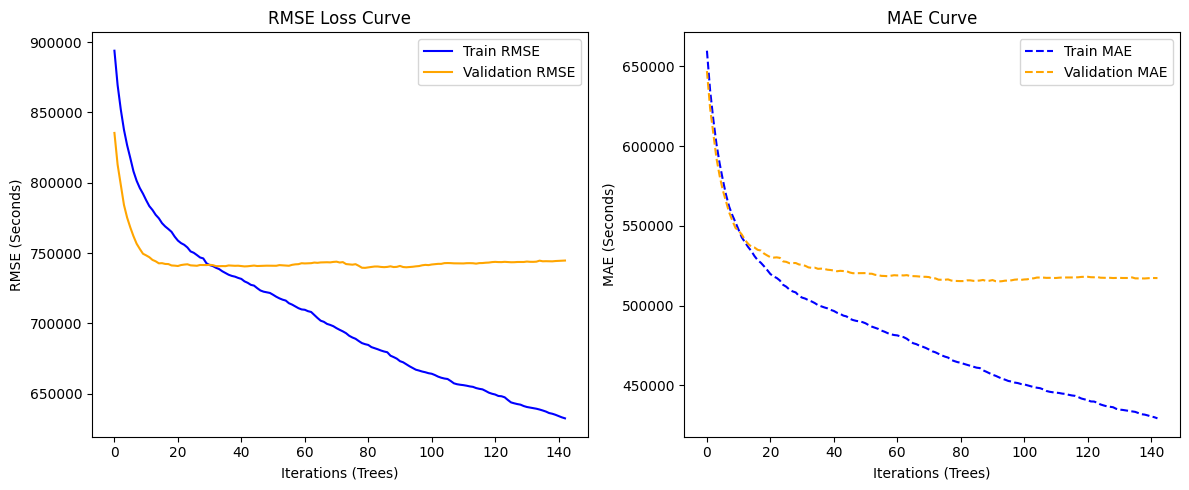

In [ ]:
import matplotlib.pyplot as plt


learning_data = catboost_model.evals_result_

train_rmse = learning_data['learn']['RMSE']
val_rmse = learning_data['validation']['RMSE']
train_mae = learning_data['learn']['MAE']
val_mae = learning_data['validation']['MAE']

plt.figure(figsize=(12, 5))

# Plot RMSE
plt.subplot(1, 2, 1)
plt.plot(train_rmse, label='Train RMSE', color='blue')
plt.plot(val_rmse, label='Validation RMSE', color='orange')
plt.title('RMSE Loss Curve')
plt.xlabel('Iterations (Trees)')
plt.ylabel('RMSE (Seconds)')
plt.legend()

# Plot MAE
plt.subplot(1, 2, 2)
plt.plot(train_mae, label='Train MAE', color='blue', linestyle='--')
plt.plot(val_mae, label='Validation MAE', color='orange', linestyle='--')
plt.title('MAE Curve')
plt.xlabel('Iterations (Trees)')
plt.ylabel('MAE (Seconds)')
plt.legend()

plt.tight_layout()
plt.show()